# Sistema predictivo de recomendación de cultivos para la optimización agrícola
## Primera Entrega: Análisis Exploratorio de Datos (EDA)

**Integrantes:**
- Jonatan Romero (`jonatan.romeroa@udea.edu.co`)
- Sebastian Berrio (`sebastian.berriom@udea.edu.co`)
- Cristian Diez (`cristian.diez@udea.edu.co`)

*Ingeniería de Sistemas — Universidad de Antioquia*

---

### 1. Configuración del entorno y librerías

Se importan las librerías para manipulación de datos (`pandas`, `numpy`), pruebas estadísticas (`scipy.stats`) y visualización (`matplotlib`, `seaborn`).

Se establece el estilo visual de las gráficas y el formato numérico de las tablas para analizar las siete variables agroclimáticas y los 22 cultivos de la base de datos.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import f_oneway

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.precision", 2)

### 2. Carga y composición general de la base de datos

Se carga el conjunto de datos público *Crop Recommendation* desde `data/Crop_recommendation.csv`, construido a partir de registros de suelo y clima. Durante la lectura se eliminan las columnas vacías residuales (`Unnamed`) y se normalizan los nombres de los macronutrientes a `N`, `P` y `K`.

A continuación se resume la estructura general del conjunto de datos: 2200 muestras, 7 variables de entrada numéricas (`N`, `P`, `K`, `temperature`, `humidity`, `ph`, `rainfall`) y la variable objetivo categórica `label` con 22 clases balanceadas.

In [2]:
ruta_archivo = Path("data/Crop_recommendation.csv")
if not ruta_archivo.exists():
    ruta_archivo = Path("../data/Crop_recommendation.csv")

df = pd.read_csv(ruta_archivo)
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]
df = df.rename(columns={"Nitrogen": "N", "phosphorus": "P", "potassium": "K"})

columnas_numericas = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
conteo_clases = df["label"].value_counts()
ir_desbalance = conteo_clases.max() / conteo_clases.min()

tabla_resumen = pd.DataFrame(
    {
        "Característica": [
            "Número de muestras",
            "Variables de entrada",
            "Variable objetivo",
            "Número de clases",
            "Muestras por clase",
            "Razón de desbalance (IR)",
            "Valores faltantes",
            "Registros duplicados",
        ],
        "Valor": [
            f"{df.shape[0]}",
            f"{len(columnas_numericas)} (numéricas)",
            "Cultivo (categórica)",
            f"{df['label'].nunique()}",
            f"{conteo_clases.iloc[0]} ({conteo_clases.iloc[0] / len(df) * 100:.2f}%)",
            f"{ir_desbalance:.2f} (balanceado)",
            f"{int(df.isnull().sum().sum())} (0%)",
            f"{int(df.duplicated().sum())}",
        ],
    }
)
display(tabla_resumen)
display(df.head())

,Característica,Valor
0,Número de muestras,2200
1,Variables de entrada,7 (numéricas)
2,Variable objetivo,Cultivo (categórica)
3,Número de clases,22
4,Muestras por clase,100 (4.55%)
5,Razón de desbalance (IR),1.00 (balanceado)
6,Valores faltantes,0 (0%)
7,Registros duplicados,0


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.88,82.00,6.50,202.94,rice
1,85,58,41,21.77,80.32,7.04,226.66,rice
2,60,55,44,23.00,82.32,7.84,263.96,rice
3,74,35,40,26.49,80.16,6.98,242.86,rice
4,78,42,42,20.13,81.60,7.63,262.72,rice


### 3. Revisión de valores faltantes, duplicados y tipos de datos

Se verifica el tipo de dato y la cantidad de valores nulos por cada columna, así como la existencia de filas duplicadas.

Al no existir valores faltantes ni registros duplicados en ninguna de las variables, no es necesario aplicar técnicas de imputación ni eliminación de registros.

In [3]:
calidad_datos = pd.DataFrame(
    {
        "Tipo de dato": df.dtypes.astype(str),
        "Valores faltantes": df.isnull().sum(),
        "Valores únicos": df.nunique(),
    }
)
display(calidad_datos)
print(f"Registros duplicados encontrados: {df.duplicated().sum()}")

,Tipo de dato,Valores faltantes,Valores únicos
N,int64,0,137
P,int64,0,117
K,int64,0,73
temperature,float64,0,2200
humidity,float64,0,2200
ph,float64,0,2200
rainfall,float64,0,2200
label,str,0,22


Registros duplicados encontrados: 0


### 4. Estadísticos descriptivos y capacidad discriminante (ANOVA)

Se calculan la media, desviación estándar, valores extremos, cuartiles, coeficiente de asimetría y el estadístico $F$ de un análisis de varianza (ANOVA) de una vía entre cada variable y el cultivo objetivo.

Los resultados muestran escalas muy diferentes entre variables (`ph` entre 3.50 y 9.94 frente a `rainfall` hasta 298.56 mm), asimetría positiva marcada en `K` (2.38) y negativa en `humidity` (-1.09). Según el estadístico $F$, el potasio (`K`), la humedad (`humidity`) y el fósforo (`P`) son las variables que mejor separan las clases.

In [4]:
descripciones = {
    "N": "Nitrógeno en el suelo",
    "P": "Fósforo en el suelo",
    "K": "Potasio en el suelo",
    "temperature": "Temperatura ambiente (°C)",
    "humidity": "Humedad relativa (%)",
    "ph": "Acidez o alcalinidad del suelo",
    "rainfall": "Precipitación (mm)",
}

filas_estadisticos = []
for col in columnas_numericas:
    grupos = [grupo[col].values for _, grupo in df.groupby("label")]
    f_stat, _ = f_oneway(*grupos)
    filas_estadisticos.append(
        {
            "Variable": col,
            "Descripción (unidad)": descripciones[col],
            "Tipo": "Entero" if pd.api.types.is_integer_dtype(df[col]) else "Real",
            "Media": df[col].mean(),
            "Desv. est.": df[col].std(),
            "Mín.": df[col].min(),
            "25%": df[col].quantile(0.25),
            "50%": df[col].median(),
            "75%": df[col].quantile(0.75),
            "Máx.": df[col].max(),
            "Asimetría": df[col].skew(),
            "F (ANOVA)": round(float(f_stat), 1),
        }
    )

df_estadisticos = pd.DataFrame(filas_estadisticos).set_index("Variable")
display(df_estadisticos)

,Descripción (unidad),Tipo,Media,Desv. est.,Mín.,25%,50%,75%,Máx.,Asimetría,F (ANOVA)
Variable,,,,,,,,,,,
N,Nitrógeno en el suelo,Entero,50.55,36.92,0.00,21.00,37.00,84.25,140.00,0.51,897.6
P,Fósforo en el suelo,Entero,53.36,32.99,5.00,28.00,51.00,68.00,145.00,1.01,1885.7
K,Potasio en el suelo,Entero,48.15,50.65,5.00,20.00,32.00,49.00,205.00,2.38,27238.4
temperature,Temperatura ambiente (°C),Real,25.62,5.06,8.83,22.77,25.60,28.56,43.68,0.18,102.2
humidity,Humedad relativa (%),Real,71.48,22.26,14.26,60.26,80.47,89.95,99.98,-1.09,3103.7
ph,Acidez o alcalinidad del suelo,Real,6.47,0.77,3.50,5.97,6.43,6.92,9.94,0.28,60.3
rainfall,Precipitación (mm),Real,103.46,54.96,20.21,64.55,94.87,124.27,298.56,0.97,605.5


### 5. Distribución de muestras por tipo de cultivo

Se grafica la frecuencia de registros para cada una de las 22 clases de cultivos presentes en la base de datos.

Cada cultivo cuenta exactamente con 100 muestras (4.55% del total), lo que garantiza un problema balanceado donde la exactitud (Accuracy) y el F1 macro tienen igual ponderación por clase.

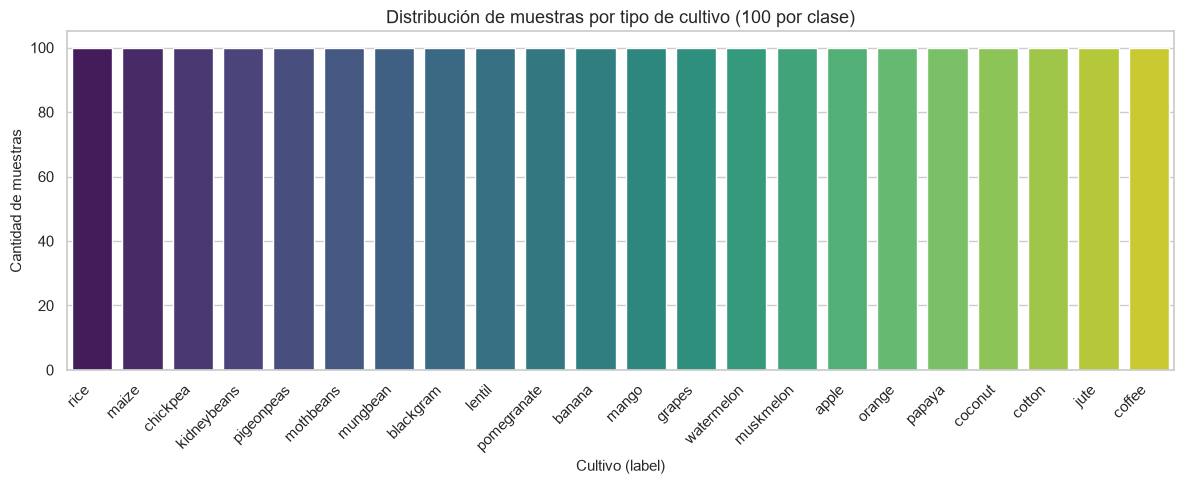

In [5]:
plt.figure(figsize=(12, 5))
sns.countplot(
    data=df,
    x="label",
    hue="label",
    palette="viridis",
    order=df["label"].value_counts().index,
    legend=False,
)
plt.title("Distribución de muestras por tipo de cultivo (100 por clase)", fontsize=13)
plt.xlabel("Cultivo (label)", fontsize=11)
plt.ylabel("Cantidad de muestras", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 6. Análisis de valores atípicos mediante rango intercuartílico (1.5 IQR)

Se identifican los valores atípicos en cada variable empleando el criterio estándar $[Q_1 - 1.5 \times \text{IQR},\; Q_3 + 1.5 \times \text{IQR}]$.

Se detectan valores atípicos principalmente en `K` (200 muestras), `P` (138) y `rainfall` (100). Al inspeccionar las clases asociadas se comprueba que no son errores de medición: por ejemplo, las 200 muestras atípicas de potasio (`K`) corresponden exactamente a los cultivos de manzana (`apple`) y uva (`grapes`), que requieren niveles cercanos a 200, por lo cual se conservan como información discriminante.

,Variable,Límite inferior,Límite superior,Muestras atípicas,Porcentaje (%),Cultivos principales en el rango atípico
0,K,-23.50,92.50,200,9.09,"grapes, apple"
1,P,-32.00,128.00,138,6.27,"apple, grapes"
2,rainfall,-25.02,213.84,100,4.55,"rice, papaya, coconut"
3,temperature,14.08,37.25,86,3.91,"papaya, grapes, orange"
4,ph,4.54,8.35,57,2.59,"mothbeans, chickpea, mango"
5,humidity,15.73,134.48,30,1.36,chickpea
6,N,-73.88,179.12,0,0.00,Ninguno


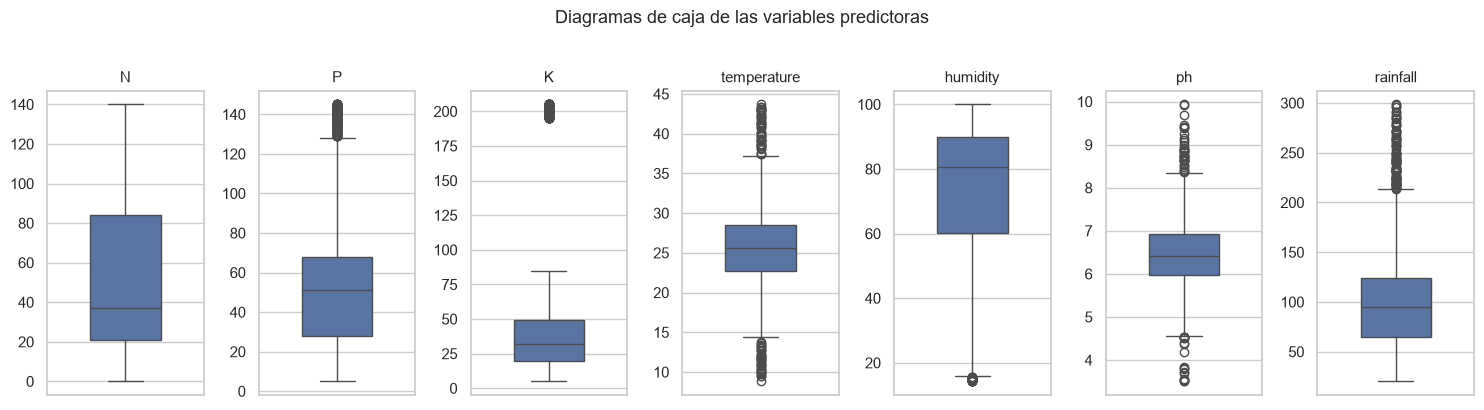

In [6]:
resumen_atipicos = []
for col in columnas_numericas:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    mask_atipicos = (df[col] < lim_inf) | (df[col] > lim_sup)
    cultivos_principales = (
        df.loc[mask_atipicos, "label"].value_counts().head(3).index.tolist()
    )
    resumen_atipicos.append(
        {
            "Variable": col,
            "Límite inferior": lim_inf,
            "Límite superior": lim_sup,
            "Muestras atípicas": int(mask_atipicos.sum()),
            "Porcentaje (%)": mask_atipicos.mean() * 100,
            "Cultivos principales en el rango atípico": ", ".join(cultivos_principales)
            if cultivos_principales
            else "Ninguno",
        }
    )

df_atipicos = pd.DataFrame(resumen_atipicos).sort_values(
    by="Muestras atípicas", ascending=False
).reset_index(drop=True)
display(df_atipicos)

fig, axes = plt.subplots(1, len(columnas_numericas), figsize=(15, 4))
for ax, col in zip(axes, columnas_numericas):
    sns.boxplot(y=df[col], ax=ax, color="#4C72B0", width=0.45)
    ax.set_title(col, fontsize=11)
    ax.set_ylabel("")
plt.suptitle("Diagramas de caja de las variables predictoras", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

### 7. Matriz de correlación de Pearson entre variables predictoras

Se calcula la correlación lineal de Pearson entre las siete variables numéricas para identificar posibles redundancias en el espacio de entrada.

La mayoría de los pares de variables presentan correlaciones débiles ($|r| < 0.25$), con excepción de fósforo (`P`) y potasio (`K`), que muestran una correlación positiva fuerte ($r = 0.74$). Esta redundancia justifica evaluar posteriormente técnicas de selección de características y reducción de dimensionalidad (PCA y UMAP).

,N,P,K,temperature,humidity,ph,rainfall
N,1.00,-0.23,-0.14,0.03,1.91e-01,9.67e-02,0.06
P,-0.23,1.00,0.74,-0.13,-1.19e-01,-1.38e-01,-0.06
K,-0.14,0.74,1.00,-0.16,1.91e-01,-1.70e-01,-0.05
temperature,0.03,-0.13,-0.16,1.00,2.05e-01,-1.78e-02,-0.03
humidity,0.19,-0.12,0.19,0.21,1.00e+00,-8.48e-03,0.09
ph,0.10,-0.14,-0.17,-0.02,-8.48e-03,1.00e+00,-0.11
rainfall,0.06,-0.06,-0.05,-0.03,9.44e-02,-1.09e-01,1.00


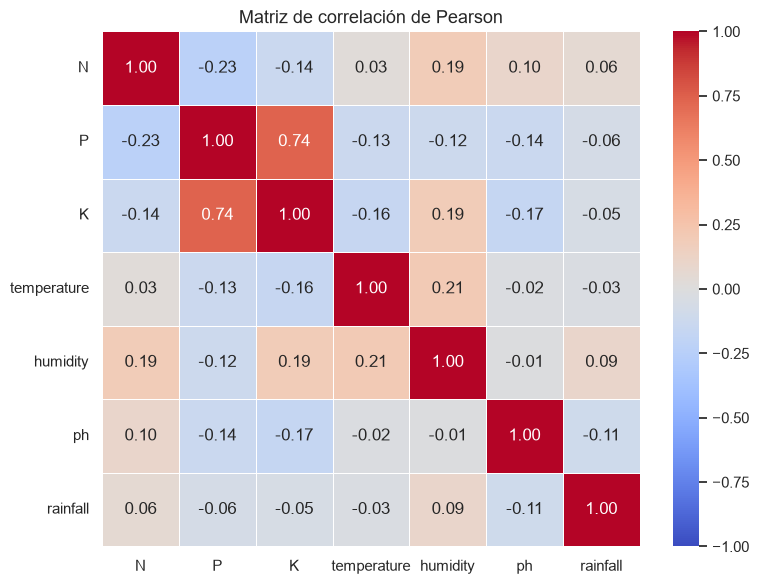

In [7]:
matriz_corr = df[columnas_numericas].corr(method="pearson")
display(matriz_corr)

plt.figure(figsize=(8, 6))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Matriz de correlación de Pearson", fontsize=13)
plt.tight_layout()
plt.show()

### 8. Separación de variables predictoras (X) y variable objetivo (y)

Finalmente, se estructuran la matriz de características `X` con las 7 variables numéricas y el vector objetivo `y` con la etiqueta del cultivo para la etapa de modelado.

Con el fin de evitar fuga de información (*data leakage*), la estandarización ($z = \frac{x - \mu}{\sigma}$) no se aplica sobre todo el conjunto de datos en este paso, sino dentro de un `Pipeline` ajustado únicamente con los datos de entrenamiento de cada partición.

In [8]:
X = df[columnas_numericas].copy()
y = df["label"].copy()

resumen_final = pd.DataFrame(
    {
        "Objeto": ["Matriz predictora (X)", "Vector objetivo (y)"],
        "Dimensiones": [str(X.shape), str(y.shape)],
        "Contenido": [
            ", ".join(X.columns),
            f"{y.nunique()} cultivos (100 muestras por clase)",
        ],
    }
)
display(resumen_final)

,Objeto,Dimensiones,Contenido
0,Matriz predictora (X),"(2200, 7)","N, P, K, temperature, humidity, ph, rainfall"
1,Vector objetivo (y),"(2200,)",22 cultivos (100 muestras por clase)


### 9. Síntesis de hallazgos del análisis exploratorio

- **Calidad y balance:** El conjunto cuenta con 2200 registros completos, sin valores faltantes ni duplicados, y perfectamente balanceados en 22 cultivos (100 muestras por clase, $\text{IR} = 1.00$).
- **Escalas heterogéneas y distribuciones no normales:** Las variables difieren hasta en dos órdenes de magnitud (`ph` frente a `rainfall`) y presentan asimetrías marcadas en `K` ($2.38$) y `humidity` ($-1.09$), por lo que es necesario estandarizarlas en modelos sensibles a la escala (Regresión Logística, KNN, SVM, MLP, PCA y UMAP).
- **Valores atípicos informativos:** Los valores extremos detectados con $1.5 \times \text{IQR}$ en `K` (200 muestras de manzana y uva) y `P` (138 muestras) corresponden a requerimientos reales de esos cultivos y se conservan.
- **Relevancia y redundancia:** Según la prueba ANOVA, `K` ($F = 27238.4$), `humidity` ($F = 3103.7$) y `P` ($F = 1885.7$) poseen la mayor capacidad discriminante, mientras que la alta correlación entre `P` y `K` ($r = 0.74$) respalda el estudio de selección de características y reducción de dimensionalidad.